#NETFLIX CONTENT RECOMMENDATION AND CLUSTERING

Objective – Build a content-based recommendation system for Netflix titles and group the catalogue into meaningful segments using K-Means clustering.

Dataset – 7,787 Netflix movies and TV shows with 12 columns: `type`, `title`, `director`, `cast`, `country`, `date_added`, `release_year`, `rating`, `duration`, `listed_in` (genres) and `description`.

## 1. Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler, LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv("NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [3]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2389
cast             718
country          507
date_added        10
release_year       0
rating             7
duration           0
listed_in          0
description        0
dtype: int64

In [4]:
df['type'].value_counts()

type
Movie      5377
TV Show    2410
Name: count, dtype: int64

In [5]:
df.nunique()

show_id         7787
type               2
title           7787
director        4049
cast            6831
country          681
date_added      1565
release_year      73
rating            14
duration         216
listed_in        492
description     7769
dtype: int64

## 2. Exploratory Data Analysis (EDA)

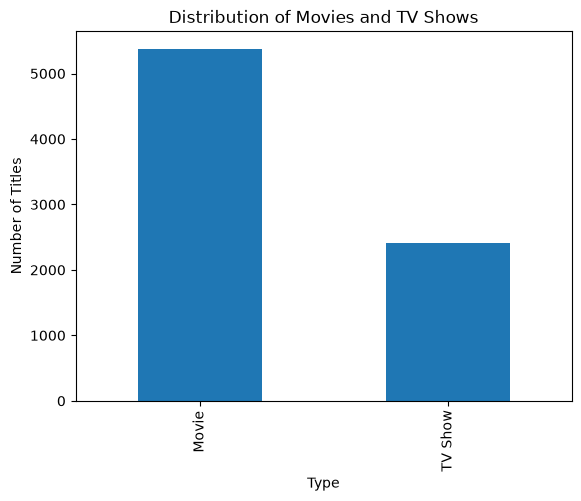

In [84]:
df['type'].value_counts().plot(kind= 'bar')
plt.title('Distribution of Movies and TV Shows')
plt.xlabel('Type')
plt.ylabel('Number of Titles')
plt.show()

Movies (5,377) clearly outnumber TV shows (2,410)
The catalogue is movie-heavy overall, but TV shows are the *newer* part of it.

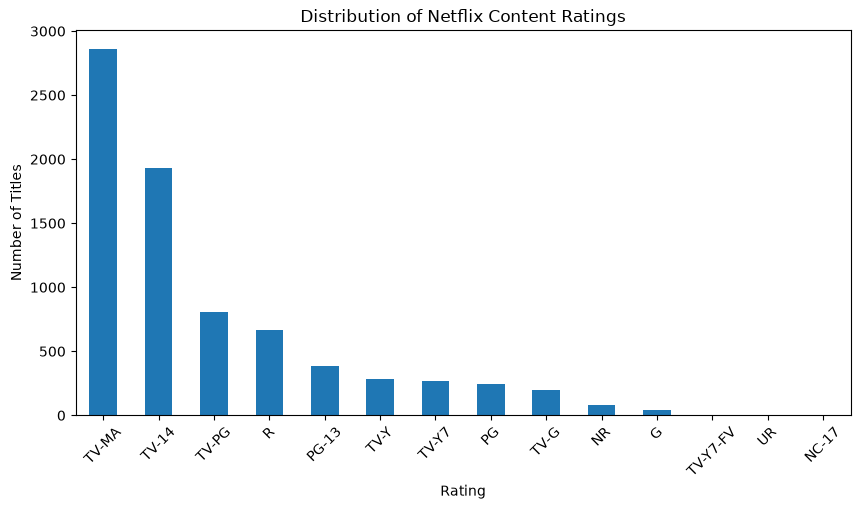

In [7]:
df['rating'].value_counts().plot(kind='bar', figsize=(10,5))
plt.title('Distribution of Netflix Content Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.show()

TV-MA (36.8 %) and TV-14 (24.8 %) are by far the most common ratings; child-oriented ratings (TV-Y, TV-G, G) are rare

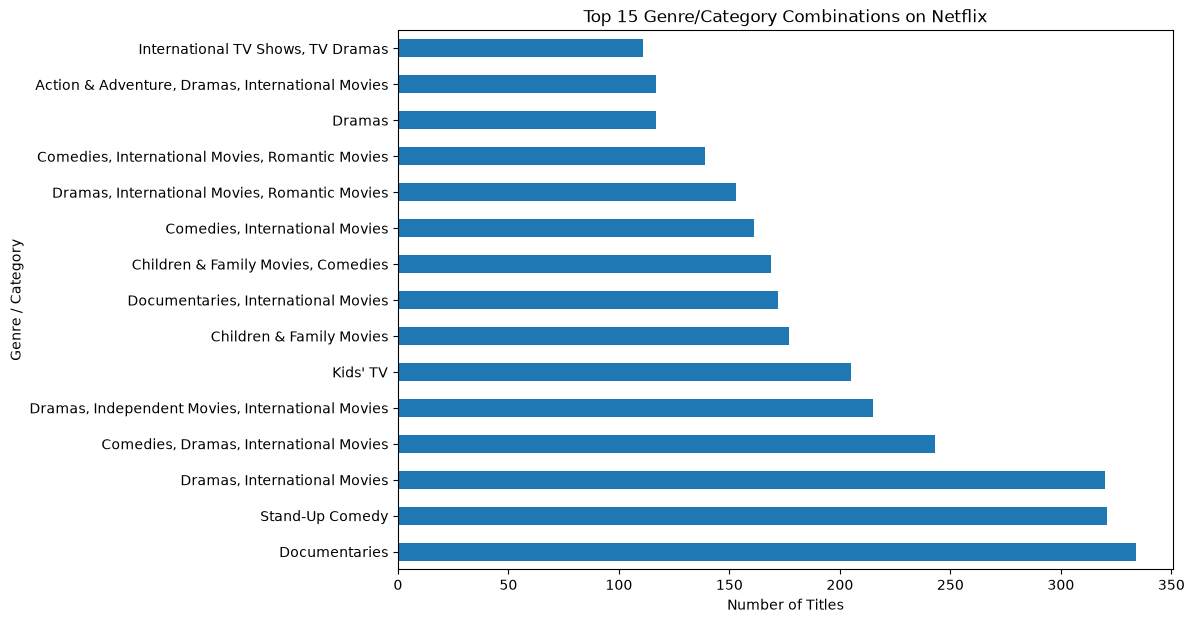

In [8]:
df['listed_in'].value_counts().head(15).plot(kind='barh', figsize=(10,7))
plt.title('Top 15 Genre/Category Combinations on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Genre / Category')
plt.show()

Genre combinations are very spread out (492 different combinations), but when each genre is counted individually, International Movies (2,437), Dramas (2,106) and Comedies (1,471) dominate.

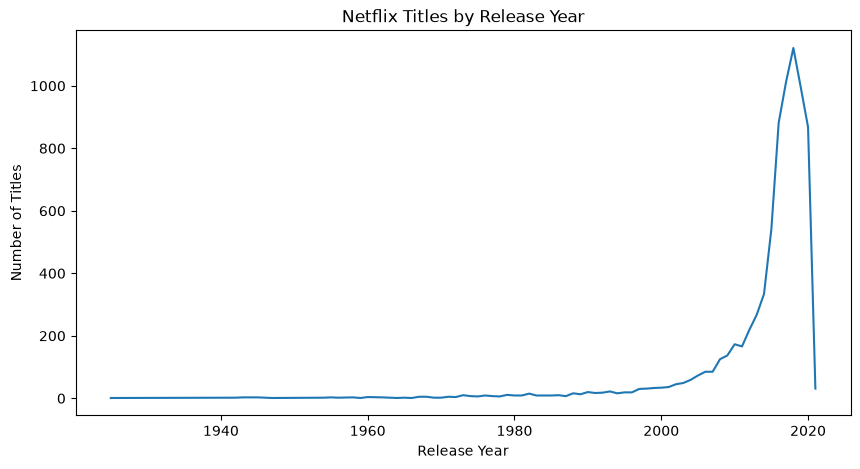

In [9]:
df['release_year'].value_counts().sort_index().plot(figsize= (10,5))
plt.title('Netflix Titles by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.show()

The number of titles rises sharply after 2010 and peaks in 2018; very few titles are older than 2000. In the most recent years TV shows catch up with movies.
 Netflix's catalogue is dominated by recent releases, and TV shows are overtaking movies among the newest content.

In [10]:
df['duration'].value_counts().head(20)

duration
1 Season     1608
2 Seasons     382
3 Seasons     184
90 min        136
93 min        131
91 min        125
94 min        125
95 min        119
92 min        118
97 min        117
96 min        115
98 min        106
103 min       101
99 min        101
88 min        101
102 min        98
100 min        97
106 min        97
101 min        96
86 min         93
Name: count, dtype: int64

In [11]:
df['country'].value_counts().head(20)

country
United States                    2555
India                             923
United Kingdom                    397
Japan                             226
South Korea                       183
Canada                            177
Spain                             134
France                            115
Egypt                             101
Mexico                            100
Turkey                            100
Australia                          83
Taiwan                             78
Brazil                             72
Philippines                        71
Nigeria                            70
Indonesia                          70
United Kingdom, United States      64
Germany                            61
United States, Canada              60
Name: count, dtype: int64

In [12]:
df[['type','country', 'release_year', 'rating', 'listed_in']].isnull().sum()

type              0
country         507
release_year      0
rating            7
listed_in         0
dtype: int64

## 3. Data cleaning

Missing value handling
Instead of deleting every row with a gap, only the columns needed for the models were treated: missing `country` and `rating` values were replaced by `'Unknown'`. `director`, `cast` and `date_added` are not model features and are left as they are (`cast` and `director` are used later only to *evaluate* the recommender). This keeps all 7,787 titles in the dataset.

In [13]:
df_clean = df.copy()
df_clean['country'] = df_clean['country'].fillna('Unknown')
df_clean['rating'] = df_clean['rating'].fillna('Unknown')

In [14]:
df_clean[['type', 'country', 'release_year', 'rating', 'listed_in']].isnull().sum()

type            0
country         0
release_year    0
rating          0
listed_in       0
dtype: int64

There are no duplicate rows. 18 descriptions are repeated across different titles; they are valid, different titles so they are kept.

In [15]:
Q1 = df['release_year'].quantile(0.25)
Q3 = df['release_year'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 2013.0
Q3: 2018.0
IQR: 5.0
Lower bound: 2005.5
Upper bound: 2025.5


In [16]:
outliers = df[
    (df['release_year'] < lower_bound) |
    (df['release_year'] > upper_bound)
]

outliers[['title', 'release_year']].sort_values('release_year')

,title,release_year
4867,Pioneers: First Women Filmmakers*,1925
4960,Prelude to War,1942
6117,The Battle of Midway,1942
7342,Undercover: How to Operate Behind Enemy Lines,1943
7616,Why We Fight: The Battle of Russia,1943
...,...,...
7745,"Yours, Mine and Ours",2005
7749,Yu-Gi-Oh!,2005
7760,Zaki Chan,2005
7782,Zozo,2005


The IQR method flags 745 titles with a release year below the lower bound of 2005.5. Inspection shows that these are legitimate older movies, documentaries and TV programmes released between 1925 and 2005, not data errors. They are therefore **kept**: removing them would delete real content and make the recommender unable to suggest classic titles.

## 4. Feature engineering

Machine-learning models need numbers, so every metadata column is converted:

`type`- TV Show = 0, Movie = 1
`rating`- One-hot Encoding (0/1)
`country`- Multi-label (a title can have several countries)
`listed_in`- (genres)- Multi-label (a title can have several genres)
`release_year`- Standardised (mean 0, standard deviation 1)
`description`- TF-IDF text

In [19]:
features = df_clean[['type', 'country', 'release_year', 'rating', 'listed_in']].copy()
features['type'] = features['type'].map({
    'TV Show' :0,
    'Movie' : 1
})

In [20]:
features['type'].head()

0    0
1    1
2    1
3    1
4    1
Name: type, dtype: int64

In [21]:
features['rating'].unique()

<ArrowStringArray>
[   'TV-MA',        'R',    'PG-13',    'TV-14',    'TV-PG',       'NR',
     'TV-G',     'TV-Y',  'Unknown',    'TV-Y7',       'PG',        'G',
    'NC-17', 'TV-Y7-FV',       'UR']
Length: 15, dtype: str

In [22]:
rating_encoded = pd.get_dummies(features['rating'], prefix = 'rating').astype(int)

In [23]:
rating_encoded.head()

,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR,rating_Unknown
0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
2,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0


In [24]:
features['country'].head(10)

0           Brazil
1           Mexico
2        Singapore
3    United States
4    United States
5           Turkey
6            Egypt
7    United States
8            India
9            India
Name: country, dtype: str

In [25]:
country_split = features['country'].str. split(',')
country_split.head(10)

0           [Brazil]
1           [Mexico]
2        [Singapore]
3    [United States]
4    [United States]
5           [Turkey]
6            [Egypt]
7    [United States]
8            [India]
9            [India]
Name: country, dtype: object

In [26]:
country_split = country_split.apply(lambda x : [country.strip() for country in x])
country_split[country_split.apply(len) > 1].head(10)

11                  [Poland, United States]
17         [Norway, Iceland, United States]
48                  [South Africa, Nigeria]
50            [United States, South Africa]
54                        [Portugal, Spain]
68            [Hong Kong, China, Singapore]
71                 [United States, Germany]
89     [South Africa, China, United States]
96          [United States, France, Serbia]
105               [Denmark, France, Poland]
Name: country, dtype: object

In [27]:
mlb = MultiLabelBinarizer()
country_encoded = mlb.fit_transform(country_split)
country_encoded.shape

(7787, 119)

In [28]:
mlb.classes_[:20]

array(['', 'Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina',
       'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas',
       'Bangladesh', 'Belarus', 'Belgium', 'Bermuda', 'Botswana',
       'Brazil', 'Bulgaria', 'Cambodia', 'Canada'], dtype=object)

In [41]:
country_encoded_df = pd.DataFrame(
    country_encoded,
    columns=['country_' + country for country in mlb.classes_]
)

In [29]:
country_split = country_split.apply(
    lambda x :['Unknown' if country == '' else country for country in x]
)

In [31]:
mlb = MultiLabelBinarizer()
country_encoded = mlb.fit_transform(country_split)
country_encoded.shape

(7787, 118)

In [32]:
mlb.classes_[:20]

array(['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina',
       'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas',
       'Bangladesh', 'Belarus', 'Belgium', 'Bermuda', 'Botswana',
       'Brazil', 'Bulgaria', 'Cambodia', 'Canada', 'Cayman Islands'],
      dtype=object)

In [35]:
genre_split = features ['listed_in'].str.split(',')
genre_split = genre_split.apply(
    lambda x : [genre.strip() for genre in x]
)

genre_split.head(10)

0    [International TV Shows, TV Dramas, TV Sci-Fi ...
1                       [Dramas, International Movies]
2                [Horror Movies, International Movies]
3    [Action & Adventure, Independent Movies, Sci-F...
4                                             [Dramas]
5    [International TV Shows, TV Dramas, TV Mysteries]
6                [Horror Movies, International Movies]
7                                             [Dramas]
8                [Horror Movies, International Movies]
9     [Horror Movies, International Movies, Thrillers]
Name: listed_in, dtype: object

In [36]:
genre_mlb = MultiLabelBinarizer()
genre_encoded = genre_mlb.fit_transform(genre_split)
genre_encoded.shape

(7787, 42)

In [37]:
genre_mlb.classes_

array(['Action & Adventure', 'Anime Features', 'Anime Series',
       'British TV Shows', 'Children & Family Movies',
       'Classic & Cult TV', 'Classic Movies', 'Comedies',
       'Crime TV Shows', 'Cult Movies', 'Documentaries', 'Docuseries',
       'Dramas', 'Faith & Spirituality', 'Horror Movies',
       'Independent Movies', 'International Movies',
       'International TV Shows', "Kids' TV", 'Korean TV Shows',
       'LGBTQ Movies', 'Movies', 'Music & Musicals', 'Reality TV',
       'Romantic Movies', 'Romantic TV Shows', 'Sci-Fi & Fantasy',
       'Science & Nature TV', 'Spanish-Language TV Shows',
       'Sports Movies', 'Stand-Up Comedy', 'Stand-Up Comedy & Talk Shows',
       'TV Action & Adventure', 'TV Comedies', 'TV Dramas', 'TV Horror',
       'TV Mysteries', 'TV Sci-Fi & Fantasy', 'TV Shows', 'TV Thrillers',
       'Teen TV Shows', 'Thrillers'], dtype=object)

In [38]:
genre_encoded_df = pd.DataFrame(
    genre_encoded, 
    columns = ['genre_' + genre for genre in genre_mlb.classes_]
)

genre_encoded_df.head()

,genre_Action & Adventure,genre_Anime Features,genre_Anime Series,genre_British TV Shows,genre_Children & Family Movies,genre_Classic & Cult TV,genre_Classic Movies,genre_Comedies,genre_Crime TV Shows,genre_Cult Movies,...,genre_TV Action & Adventure,genre_TV Comedies,genre_TV Dramas,genre_TV Horror,genre_TV Mysteries,genre_TV Sci-Fi & Fantasy,genre_TV Shows,genre_TV Thrillers,genre_Teen TV Shows,genre_Thrillers
0,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,1,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [39]:
basic_features = features[['type', 'release_year']].copy()

In [42]:
ml_data = pd.concat(
    [ basic_features,
        rating_encoded,
        country_encoded_df,
        genre_encoded_df
    ],
    axis=1
)

In [44]:
scaler = StandardScaler()
ml_data['release_year'] = scaler.fit_transform(
    ml_data[['release_year']]
)
ml_data['release_year'].describe()

count    7.787000e+03
mean     1.003173e-14
std      1.000064e+00
min     -1.015579e+01
25%     -1.064974e-01
50%      3.502888e-01
75%      4.644853e-01
max      8.070750e-01
Name: release_year, dtype: float64

In [45]:
x = ml_data.values
x.shape

(7787, 177)

In [46]:
similarity_matrix = cosine_similarity(x)
similarity_matrix.shape

(7787, 7787)

In [47]:
titles = df_clean['title'].reset_index(drop =True)
titles.head(10)

0       3%
1     7:19
2    23:59
3        9
4       21
5       46
6      122
7      187
8      706
9     1920
Name: title, dtype: str

In [48]:
def recommend_with_scores(title):
    if title not in titles.values:
        return "Sorry, that title is not in the dataset."

    title_index = titles[titles == title].index[0]

    similarity_scores = similarity_matrix[title_index]

    similar_indices = similarity_scores.argsort()[::-1]

    similar_indices = similar_indices[1:6]

    recommendation_scores = similarity_scores[similar_indices]

    recommendations = []

    for index, score in zip(similar_indices, recommendation_scores):
        recommendations.append(
            (titles.iloc[index], float(round(score,4)))
        )

    return recommendations

In [49]:
recommend_with_scores("Biohackers")

[('Unorthodox', 0.9042),
 ('Holiday Secrets', 0.903),
 ('Charité', 0.8926),
 ('The Last Word', 0.8175),
 ('Oktoberfest: Beer & Blood', 0.8175)]

In [51]:
results = recommend_with_scores("Biohackers")

In [52]:
print ("Recommendations for Biohackers\n")
for i, (title,score) in enumerate(results, start=1):
    print(f"{i}. {title} — Similarity: {score:.4f}")

Recommendations for Biohackers

1. Unorthodox — Similarity: 0.9042
2. Holiday Secrets — Similarity: 0.9030
3. Charité — Similarity: 0.8926
4. The Last Word — Similarity: 0.8175
5. Oktoberfest: Beer & Blood — Similarity: 0.8175


In [53]:
features.loc[titles == "3%"]

,type,country,release_year,rating,listed_in
0,0,Brazil,2020,TV-MA,"International TV Shows, TV Dramas, TV Sci-Fi &..."


In [54]:
features.loc[titles == "Omniscient"]

,type,country,release_year,rating,listed_in
4611,0,Brazil,2020,TV-MA,"International TV Shows, TV Dramas, TV Sci-Fi &..."


In [55]:
df_clean['description'].head()

0    In a future where the elite inhabit an island ...
1    After a devastating earthquake hits Mexico Cit...
2    When an army recruit is found dead, his fellow...
3    In a postapocalyptic world, rag-doll robots hi...
4    A brilliant group of students become card-coun...
Name: description, dtype: str

In [56]:
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df_clean['description'])
tfidf_similarity = cosine_similarity(tfidf_matrix)

In [57]:
title_index_3 = titles[titles == "3%"].index[0]
title_index_omniscient = titles[titles == "Omniscient"].index[0]
tfidf_similarity[title_index_3, title_index_omniscient]

np.float64(0.0)

In [58]:
hybrid_similarity= (
    0.4*similarity_matrix
    + 0.6*tfidf_similarity
)

hybrid_similarity[title_index_3, title_index_omniscient]

np.float64(0.3999999999999999)

In [59]:
def hybrid_recommend(title):
    if title not in titles.values:
        return "Sorry, that title is not in the dataset."

    title_index = titles[titles == title].index[0]

    similarity_scores = hybrid_similarity[title_index]

    similar_indices = similarity_scores.argsort()[::-1]

    similar_indices = similar_indices[1:6]

    recommendation_scores = similarity_scores[similar_indices]

    recommendations = []

    for index, score in zip(similar_indices, recommendation_scores):
        recommendations.append(
            (titles.iloc[index], float(round(score, 4)))
        )

    return recommendations

In [60]:
hybrid_recommend("3%")

[('Omniscient', 0.4),
 ('Biohackers', 0.327),
 ('Most Beautiful Thing', 0.327),
 ('Kissing Game', 0.327),
 ('The Stranded', 0.3265)]

In [61]:
bio_index = titles[titles == "Biohackers"].index[0]

print("Metadata:", similarity_matrix[title_index_3, bio_index])
print("Description:", tfidf_similarity[title_index_3, bio_index])
print("Hybrid:", hybrid_similarity[title_index_3, bio_index])

Metadata: 0.8175209285819018
Description: 0.0
Hybrid: 0.32700837143276074


In [62]:
recommended_titles = [title for title, score in hybrid_recommend("3%")]

df_clean[df_clean["title"].isin(recommended_titles)][
    ["title", "country", "release_year", "rating", "listed_in", "description"]
]

,title,country,release_year,rating,listed_in,description
931,Biohackers,Germany,2020,TV-MA,"International TV Shows, TV Dramas, TV Sci-Fi &...",A medical student enters a top German universi...
3416,Kissing Game,Brazil,2020,TV-MA,"International TV Shows, TV Dramas, TV Mysteries","At a high school in a rural, isolated ranching..."
4233,Most Beautiful Thing,Brazil,2020,TV-MA,"International TV Shows, Romantic TV Shows, TV ...",A 1950s housewife goes to Rio de Janeiro to me...
4611,Omniscient,Brazil,2020,TV-MA,"International TV Shows, TV Dramas, TV Sci-Fi &...","In a city where citizens are monitored 24/7, a..."
6907,The Stranded,Thailand,2019,TV-MA,"International TV Shows, TV Action & Adventure,...","Trapped on an island destroyed by a tsunami, t..."


In [63]:
def final_recommend(title):
    title = title.strip()

    matching_titles = titles[titles.str.lower() == title.lower()]

    if matching_titles.empty:
        print("Sorry, that title is not in the dataset.")
        return

    title_index = matching_titles.index[0]

    similarity_scores = hybrid_similarity[title_index]

    similar_indices = similarity_scores.argsort()[::-1]

    similar_indices = similar_indices[1:6]

    print(f"\nRecommendations for: {titles.iloc[title_index]}\n")

    for rank, index in enumerate(similar_indices, start=1):
        score = round(similarity_scores[index], 4)
        print(f"{rank}. {titles.iloc[index]} — Similarity: {score}")

In [64]:
final_recommend("3%")


Recommendations for: 3%

1. Omniscient — Similarity: 0.4
2. Biohackers — Similarity: 0.327
3. Most Beautiful Thing — Similarity: 0.327
4. Kissing Game — Similarity: 0.327
5. The Stranded — Similarity: 0.3265


In [65]:
bio_recommendations = [title for title, score in hybrid_recommend("3%")]

df_clean[df_clean["title"].isin(bio_recommendations)][
    ["title", "country", "release_year", "rating", "listed_in", "description"]
]

,title,country,release_year,rating,listed_in,description
931,Biohackers,Germany,2020,TV-MA,"International TV Shows, TV Dramas, TV Sci-Fi &...",A medical student enters a top German universi...
3416,Kissing Game,Brazil,2020,TV-MA,"International TV Shows, TV Dramas, TV Mysteries","At a high school in a rural, isolated ranching..."
4233,Most Beautiful Thing,Brazil,2020,TV-MA,"International TV Shows, Romantic TV Shows, TV ...",A 1950s housewife goes to Rio de Janeiro to me...
4611,Omniscient,Brazil,2020,TV-MA,"International TV Shows, TV Dramas, TV Sci-Fi &...","In a city where citizens are monitored 24/7, a..."
6907,The Stranded,Thailand,2019,TV-MA,"International TV Shows, TV Action & Adventure,...","Trapped on an island destroyed by a tsunami, t..."


In [66]:
original_genres = set(
    df_clean[df_clean["title"] == "3%"]["listed_in"].iloc[0].split(", ")
)

for title, score in hybrid_recommend("3%"):
    recommended_genres = set(
        df_clean[df_clean["title"] == title]["listed_in"].iloc[0].split(", ")
    )

    overlap = original_genres.intersection(recommended_genres)

    print(f"{title}:")
    print(f"  Shared genres: {overlap}")
    print()

Omniscient:
  Shared genres: {'TV Sci-Fi & Fantasy', 'International TV Shows', 'TV Dramas'}

Biohackers:
  Shared genres: {'TV Sci-Fi & Fantasy', 'International TV Shows', 'TV Dramas'}

Most Beautiful Thing:
  Shared genres: {'International TV Shows', 'TV Dramas'}

Kissing Game:
  Shared genres: {'International TV Shows', 'TV Dramas'}

The Stranded:
  Shared genres: {'International TV Shows', 'TV Dramas'}



In [67]:
print("=" * 50)
print("       NETFLIX RECOMMENDATION SYSTEM")
print("=" * 50)

while True :
    user_title = input ("\nEnter a Netflix title(or type 'exit' to stop): ")
    if user_title.lower() == "exit" :
        print ("Thank you for using Netflix Recommender! ")
        break

    final_recommend(user_title)

       NETFLIX RECOMMENDATION SYSTEM



Enter a Netflix title(or type 'exit' to stop):  3%



Recommendations for: 3%

1. Omniscient — Similarity: 0.4
2. Biohackers — Similarity: 0.327
3. Most Beautiful Thing — Similarity: 0.327
4. Kissing Game — Similarity: 0.327
5. The Stranded — Similarity: 0.3265



Enter a Netflix title(or type 'exit' to stop):  exit


Thank you for using Netflix Recommender! 


In [68]:
title = "3%"

title_index = titles[titles == title].index[0]

original_genres = set(
    df_clean.loc[title_index, "listed_in"].split(", ")
)

print("Genres of", title, ":")
print(original_genres)

Genres of 3% :
{'TV Sci-Fi & Fantasy', 'International TV Shows', 'TV Dramas'}


In [69]:
recommended_titles = [
    "Omniscient",
    "Biohackers",
    "Most Beautiful Thing",
    "Kissing Game",
    "The Stranded"
]

for rec_title in recommended_titles:
    rec_index = titles[titles == rec_title].index[0]

    rec_genres = set(
        df_clean.loc[rec_index, "listed_in"].split(", ")
    )

    common_genres = original_genres.intersection(rec_genres)

    print(rec_title, "→", len(common_genres), "common genres")
    print(common_genres)
    print()
    

Omniscient → 3 common genres
{'TV Sci-Fi & Fantasy', 'International TV Shows', 'TV Dramas'}

Biohackers → 3 common genres
{'TV Sci-Fi & Fantasy', 'International TV Shows', 'TV Dramas'}

Most Beautiful Thing → 2 common genres
{'International TV Shows', 'TV Dramas'}

Kissing Game → 2 common genres
{'International TV Shows', 'TV Dramas'}

The Stranded → 2 common genres
{'International TV Shows', 'TV Dramas'}



In [70]:
matched = 0

for rec_title in recommended_titles:
    rec_index = titles[titles == rec_title].index[0]

    rec_genres = set(
        df_clean.loc[rec_index, "listed_in"].split(", ")
    )

    if original_genres.intersection(rec_genres):
        matched += 1

genre_match_rate = (matched / len(recommended_titles)) * 100

print("Genre Match Rate:", genre_match_rate, "%")

Genre Match Rate: 100.0 %


In [71]:
test_titles = [
    "3%",
    "Biohackers",
    "Friends",
    "The Office (U.S.)",
    "Unorthodox"
]

for title in test_titles:

    title_index = titles[titles == title].index[0]

    original_genres = set(
        df_clean.loc[title_index, "listed_in"].split(", ")
    )

    similarity_scores = hybrid_similarity[title_index]

    similar_indices = similarity_scores.argsort()[::-1][1:6]

    matched = 0

    for index in similar_indices:

        rec_genres = set(
            df_clean.loc[index, "listed_in"].split(", ")
        )

        if original_genres.intersection(rec_genres):
            matched += 1

    genre_match_rate = (matched / 5) * 100

    print(f"{title}: {genre_match_rate}%")

3%: 100.0%
Biohackers: 100.0%
Friends: 100.0%
The Office (U.S.): 100.0%
Unorthodox: 100.0%


The hybrid recommendation system achieved an average Genre Match Rate of 100% across the five selected test titles: 3%, Biohackers, Friends, The Office (U.S.), and Unorthodox.
For each test title, all five recommended titles shared at least one genre with the input title. This indicates that the recommendation system consistently produces content that is thematically related to the selected title.
However, this result should be interpreted as a content-based evaluation rather than a measure of prediction accuracy or user satisfaction, because the dataset does not contain user ratings, viewing history, or explicit preference data

In [72]:
df['duration_numeric'] = df['duration'].str.extract('(\d+)').astype(float)
df[['type', 'release_year', 'duration', 'duration_numeric']].head()

,type,release_year,duration,duration_numeric
0,TV Show,2020,4 Seasons,4.0
1,Movie,2016,93 min,93.0
2,Movie,2011,78 min,78.0
3,Movie,2009,80 min,80.0
4,Movie,2008,123 min,123.0


In [73]:
le = LabelEncoder()

df['type_encoded'] = le.fit_transform(df['type'])
df[['type', 'type_encoded']].drop_duplicates()

,type,type_encoded
0,TV Show,1
1,Movie,0


In [74]:
kmeans_data = df[
    ['release_year', 'duration_numeric', 'type_encoded']
].dropna()

kmeans_data.shape

(7787, 3)

In [75]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(kmeans_data)

In [76]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    
    inertia.append(kmeans.inertia_)

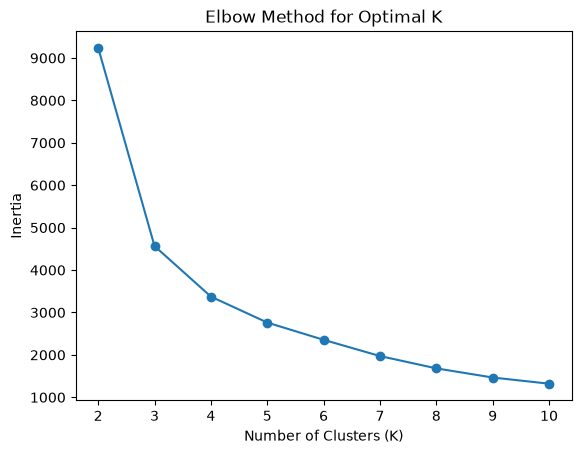

In [77]:
plt.plot(range(2, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.show()

Why K = 3?
The elbow plot bends around K = 3: adding more clusters after that gives much smaller drops in inertia.

In [78]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 3)","[[ 0.

In [79]:
kmeans_data['cluster'] = kmeans.labels_
kmeans_data['cluster'].value_counts().sort_index()

cluster
0    4937
1    2393
2     457
Name: count, dtype: int64

In [80]:
kmeans_data.groupby('cluster')[['release_year', 'duration_numeric', 'type_encoded']].mean()

,release_year,duration_numeric,type_encoded
cluster,,,
0,2015.291067,97.840186,0.000000
1,2016.488926,1.765984,1.000000
2,1985.870897,111.588621,0.037199


In [81]:
pd.crosstab(kmeans_data['cluster'], df.loc[kmeans_data.index, 'type'])

type,Movie,TV Show
cluster,,
0,4937,0
1,0,2393
2,440,17


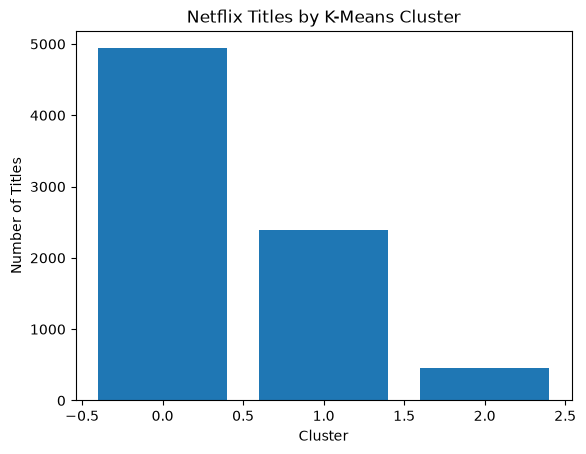

In [82]:
cluster_counts = kmeans_data['cluster'].value_counts().sort_index()

plt.bar(cluster_counts.index, cluster_counts.values)

plt.xlabel('Cluster')
plt.ylabel('Number of Titles')
plt.title('Netflix Titles by K-Means Cluster')

plt.show()

The K-Means clustering model divided Netflix content into three distinct groups based on release year, duration, and content type.

Cluster 0 – Recent Movies: This is the largest cluster, consisting of 4,937 movies with an average release year of around 2015 and an average duration of approximately 98 minutes. 
 Netflix can focus on promoting these movies through personalized recommendations and targeted campaigns.

Cluster 1 – TV Shows: This cluster contains 2,393 TV shows, with an average release year of around 2016 and approximately 2 seasons per show. 
 Netflix can use this segment to encourage continued viewing through personalized series recommendations and new-season notifications.

Cluster 2 – Older Content: This smaller cluster contains 457 titles, predominantly older movies, with an average release year of around 1986 and an average duration of approximately 112 minutes. 
 Netflix can target this segment toward users interested in classic, older, or nostalgic content.

Overall, the clustering strategy helps Netflix understand different content segments and can support personalized recommendations, targeted promotions, and better content categorization

Who is this useful for?
Let me explain who benefits, because a project is only valuable if it helps someone.

1) The viewers. A recommender helps them discover content they're likely to enjoy without scrolling endlessly.
2) The product and recommendation team. A content-based approach works even when there is no user history. This is called the cold-start problem, for example when a new user joins or a brand-new show is added. A system built on content features can recommend that new show immediately, because it only needs the show's details.
3) The marketing team. Clusters show the types of content that exist, so they can design targeted campaigns, such as promoting recent movies to one audience and classic content to another.
4) The content strategy team. Understanding the catalogue, for example how much of it is movies versus TV shows, which ratings dominate, and how much is older content, can inform what Netflix should acquire or produce next.

LIMITATION- NO real user data, the evaluation is a sanity check rather than real accuracy, and the hybrid weights weren't tuned.